# 03 — Feature engineering: test every idea

**Goal of this notebook:** try each feature idea, measure it honestly, and decide what goes into
`engineer_features()` in `common.py`.

**The loop:** change one thing → measure validation PR-AUC → compare with the baseline → keep or
drop → record the result, including what did *not* work.

**Three rules every idea here follows** (they come from `common.py`):

1. **Row by row only.** A feature may use that person's own answers and fixed constants such as
   "Poor = 0", never statistics computed from the dataset such as "the average BMI". Those would
   leak test information into training.
2. **Numbers for numbers, text for categories.** A new numeric column is scaled as a number; a new
   text column is one-hot encoded.
3. **Replace, don't duplicate.** If a new column replaces a raw one, the raw one is dropped.

**The test set is never used here.** Everything is measured on validation, exactly as `train.py`
chooses C and the threshold.

The ideas that survived are listed in section 10 as `FINAL_IDEAS`, and section 11 shows the
repeated-shuffle evidence behind that choice.


## 0. Setup

Same data, same split, same pipeline as `train.py` and notebook 02.

In [1]:
import os
import sys
import importlib
import subprocess
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)

TARGET = "HadHeartAttack"
SEED = 42
C_GRID = [0.0001, 0.001, 0.01, 0.1, 1.0, 10.0]     # same grid as train.py

URL = "https://raw.githubusercontent.com/Wilrick1234/daiist-assignment-1/main/data/heart_2022_sample.csv"
if os.path.exists("data/heart_2022_sample.csv"):
    raw = pd.read_csv("data/heart_2022_sample.csv")      # running inside the repo
else:
    raw = pd.read_csv(URL)                                # running in Colab

raw = raw.dropna(subset=[TARGET])

# Same split as train.py. The test rows are set aside and never used in this notebook.
train_val, test = train_test_split(raw, test_size=0.20, stratify=raw[TARGET], random_state=SEED)
print(f"Working with {len(train_val):,} train+validation rows. {len(test):,} test rows untouched.")

Working with 16,000 train+validation rows. 4,000 test rows untouched.


## 1. Lookup tables

Fixed constants used by the ideas below. Because they're written by hand (not computed from the
data), they're safe to use row by row.

In [2]:
HEALTH_RANK = {"Poor": 0, "Fair": 1, "Good": 2, "Very good": 3, "Excellent": 4}   # 0 = bad, 4 = good

AGE_ORDER = ["Age 18 to 24", "Age 25 to 29", "Age 30 to 34", "Age 35 to 39", "Age 40 to 44",
             "Age 45 to 49", "Age 50 to 54", "Age 55 to 59", "Age 60 to 64", "Age 65 to 69",
             "Age 70 to 74", "Age 75 to 79", "Age 80 or older"]
AGE_RANK = {age: i for i, age in enumerate(AGE_ORDER)}                             # 0 ... 12
AGE_YEARS = {"Age 18 to 24": 21, "Age 25 to 29": 27, "Age 30 to 34": 32, "Age 35 to 39": 37,
             "Age 40 to 44": 42, "Age 45 to 49": 47, "Age 50 to 54": 52, "Age 55 to 59": 57,
             "Age 60 to 64": 62, "Age 65 to 69": 67, "Age 70 to 74": 72, "Age 75 to 79": 77,
             "Age 80 or older": 85}                                                # middle of each band

CHECKUP_RANK = {"Within past year (anytime less than 12 months ago)": 0,
                "Within past 2 years (1 year but less than 2 years ago)": 1,
                "Within past 5 years (2 years but less than 5 years ago)": 2,
                "5 or more years ago": 3}
CHECKUP_YEARS = {"Within past year (anytime less than 12 months ago)": 0.5,
                 "Within past 2 years (1 year but less than 2 years ago)": 1.5,
                 "Within past 5 years (2 years but less than 5 years ago)": 3.5,
                 "5 or more years ago": 7.0}                                       # rough years ago

SMOKING_RANK = {"Never smoked": 0, "Former smoker": 1,
                "Current smoker - now smokes some days": 2, "Current smoker - now smokes every day": 3}
ECIG_RANK = {"Never used e-cigarettes in my entire life": 0, "Not at all (right now)": 1,
             "Use them some days": 2, "Use them every day": 3}
TEETH_RANK = {"None of them": 0, "1 to 5": 1, "6 or more, but not all": 2, "All": 3}

DISABILITY_COLUMNS = ["DifficultyWalking", "DifficultyErrands", "DifficultyDressingBathing",
                      "DifficultyConcentrating", "DeafOrHardOfHearing", "BlindOrVisionDifficulty"]

STROKE_BELT = ["Alabama", "Arkansas", "Georgia", "Louisiana", "Mississippi",
               "North Carolina", "South Carolina", "Tennessee"]
REGION = {}
for state in ["Connecticut", "Maine", "Massachusetts", "New Hampshire", "Rhode Island", "Vermont",
              "New Jersey", "New York", "Pennsylvania"]:
    REGION[state] = "Northeast"
for state in ["Illinois", "Indiana", "Michigan", "Ohio", "Wisconsin", "Iowa", "Kansas", "Minnesota",
              "Missouri", "Nebraska", "North Dakota", "South Dakota"]:
    REGION[state] = "Midwest"
for state in ["Delaware", "District of Columbia", "Florida", "Georgia", "Maryland", "North Carolina",
              "South Carolina", "Virginia", "West Virginia", "Alabama", "Kentucky", "Mississippi",
              "Tennessee", "Arkansas", "Louisiana", "Oklahoma", "Texas"]:
    REGION[state] = "South"
for state in ["Arizona", "Colorado", "Idaho", "Montana", "Nevada", "New Mexico", "Utah", "Wyoming",
              "Alaska", "California", "Hawaii", "Oregon", "Washington"]:
    REGION[state] = "West"
for state in ["Guam", "Puerto Rico", "Virgin Islands"]:
    REGION[state] = "Territory"

# Health conditions to count (the target and HadAngina left out on purpose, see n_chronic)
CONDITIONS_TO_COUNT = ["HadStroke", "HadAsthma", "HadSkinCancer", "HadCOPD", "HadDepressiveDisorder",
                       "HadKidneyDisease", "HadArthritis", "HadDiabetes"]

## 2. The ideas, one by one

Every idea is a small function with the same shape:

```python
def some_idea(df):
    df["new_column"] = ...        # add the new column(s)
    return ["RawColumn"]          # the raw columns it REPLACES (empty list if it only adds)
```

The replaced columns are not dropped inside the function; they are dropped at the very end. That
way every idea still sees the original raw data, whichever other ideas are switched on.

Two decisions from notebook 01 are not functions and so do not appear below:

- **One-hot for RaceEthnicityCategory** is already what the baseline does to every text column, so
  there is nothing to switch on. The point is *why*: race has no natural order.
- **No time-based split** is a decision about splitting, not a feature (see notebook 02).

---
## 2a. Ordered text → one number

These replace several one-hot columns with **one** number. One coefficient instead of many means
less noise, but it assumes the categories are **evenly spaced** and that the effect runs in one
direction.


### `health_rank`

**What it does:** GeneralHealth → one number: Poor = 0, Fair = 1, Good = 2, Very good = 3, Excellent = 4. Replaces 4 one-hot columns.

**Why it might help:** Notebook 01, section 5: each step up the scale roughly doubles the heart attack rate. That's a straight line in log-odds, exactly what one number assumes.

**What could go wrong:** Not much. If the steps weren't even, one number would fit worse than four separate columns.

In [3]:
def health_rank(df):
    df["health_rank"] = df["GeneralHealth"].map(HEALTH_RANK)
    return ["GeneralHealth"]

### `age_rank`

**What it does:** AgeCategory → 0 (18 to 24) up to 12 (80 or older). Replaces 12 one-hot columns.

**Why it might help:** The rate climbs steadily with age, and the youngest groups have only 3 to 11 heart attacks each, so 12 separate coefficients are noisy. One coefficient uses all rows.

**What could go wrong:** It forces a straight line. Notebook 01 showed age is flat-ish below 40, so the youngest groups may fit a bit worse.

In [4]:
def age_rank(df):
    df["age_rank"] = df["AgeCategory"].map(AGE_RANK)
    return ["AgeCategory"]

### `checkup_rank`

**What it does:** LastCheckupTime → 0 (past year), 1 (past 2 years), 2 (past 5 years), 3 (5+ years).

**Why it might help:** Fewer columns, and the categories have a natural order.

**What could go wrong:** Notebook 01 showed this isn't a steady trend: only "past year" stands out, and mostly because of age. Evenly spaced numbers may describe it badly.

In [5]:
def checkup_rank(df):
    df["checkup_rank"] = df["LastCheckupTime"].map(CHECKUP_RANK)
    return ["LastCheckupTime"]

### `smoking_rank`

**What it does:** SmokerStatus → 0 (never), 1 (former), 2 (some days), 3 (every day).

**Why it might help:** Within age bands (notebook 01, section 8) the order never < former < current mostly holds.

**What could go wrong:** It assumes the jump from never to former is the same size as from former to daily. The EDA suggests the biggest jump is never → ever.

In [6]:
def smoking_rank(df):
    df["smoking_rank"] = df["SmokerStatus"].map(SMOKING_RANK)
    return ["SmokerStatus"]

### `ecig_rank`

**What it does:** ECigaretteUsage → 0 (never), 1 (not right now), 2 (some days), 3 (every day).

**Why it might help:** Natural order, fewer columns.

**What could go wrong:** The raw rates go the *wrong* way (users look safer) because users are young. The model also sees age, so it can correct for that, but this column is weak either way.

In [7]:
def ecig_rank(df):
    df["ecig_rank"] = df["ECigaretteUsage"].map(ECIG_RANK)
    return ["ECigaretteUsage"]

### `teeth_rank`

**What it does:** RemovedTeeth → 0 (none), 1 (1 to 5), 2 (6+), 3 (all).

**Why it might help:** A clean, steady climb (2.6% → 6.2% → 12.7% → 18.0%) that survives the within-age check.

**What could go wrong:** Little. The steps aren't perfectly even, but close.

In [8]:
def teeth_rank(df):
    df["teeth_rank"] = df["RemovedTeeth"].map(TEETH_RANK)
    return ["RemovedTeeth"]

---
## 2b. Other column-level ideas


### `drop_height_weight`

**What it does:** Removes HeightInMeters and WeightInKilograms, keeps BMI.

**Why it might help:** BMI = weight ÷ height², so the three columns hold two pieces of information. BMI and weight correlate at 0.86, and within each sex height and weight showed no clear trend.

**What could go wrong:** Height and BMI are almost unrelated (−0.02), so dropping height throws away a little information that BMI doesn't contain.

In [9]:
def drop_height_weight(df):
    return ["HeightInMeters", "WeightInKilograms"]

### `difficulties_count`

**What it does:** Replaces the six Difficulty / hearing / vision columns with one count from 0 to 6.

**Why it might help:** The six questions point the same way, and more difficulties means more heart attacks in every age band. Six coefficients become one.

**What could go wrong:** It forces every difficulty to count the same. They're only moderately related (0.10 to 0.42), so some information is lost.

In [10]:
def difficulties_count(df):
    df["n_difficulties"] = (df[DISABILITY_COLUMNS] == "Yes").sum(axis=1)
    return DISABILITY_COLUMNS

**Compressing State.** The baseline already gives each state its own one-hot column, so "does one
state have more than another?" is in the model as 53 columns. The real question is whether those
53 columns are worth it. The next two ideas test two ways to **compress** them.

A third way, replacing each state with *its heart attack rate*, is called **target encoding**. It
is not used here because it is a statistic computed from the data: it would have to be learned on
the training rows only, inside the sklearn pipeline, rather than row by row.


### `region`

**What it does:** Replaces State (53 columns) with the US Census region: Northeast, Midwest, South, West, Territory (4 one-hot columns).

**Why it might help:** Each state has only about 15 heart attacks, so most state coefficients are noise. Notebook 01 showed a real regional pattern (South 1.16 × expected).

**What could go wrong:** Real differences between states in the same region are lost.

In [11]:
def region(df):
    df["region"] = df["State"].map(REGION)
    return ["State"]

### `stroke_belt`

**What it does:** Replaces State with one 0/1 flag: is this person in one of the 8 Stroke Belt states?

**Why it might help:** Notebook 01 found the Stroke Belt at 1.23 × the expected heart attacks. One
column instead of 53.

**What could go wrong:** the most extreme compression available here — everything except "Stroke
Belt or not" is thrown away. The eight-state definition is the CDC's conventional one
(Alabama, Arkansas, Georgia, Louisiana, Mississippi, North Carolina, South Carolina, Tennessee).


In [12]:
def stroke_belt(df):
    df["stroke_belt"] = df["State"].isin(STROKE_BELT).astype(int)
    return ["State"]

---
## 2c. Variants

The same columns turned into numbers a different way. At most **one** from each pair belongs in a
feature set, never both.


### `age_years` (variant of `age_rank`)

**What it does:** AgeCategory → the middle of the band in years (21, 27, 32 ... 85).

**Why it might help:** Almost the same as age_rank, but the gaps are real years (the first band is 7 years wide, 80+ is open). The coefficient reads as "per year".

**What could go wrong:** Same as age_rank: it forces a straight line.

In [13]:
def age_years(df):
    df["age_years"] = df["AgeCategory"].map(AGE_YEARS)
    return ["AgeCategory"]

### `checkup_years` (variant of `checkup_rank`)

**What it does:** LastCheckupTime → rough years since the checkup (0.5, 1.5, 3.5, 7).

**Why it might help:** Says the gap between "2 to 5 years" and "5+ years" is bigger than between "under 1" and "1 to 2".

**What could go wrong:** Same problem as checkup_rank: the EDA showed a jump, not a trend.

In [14]:
def checkup_years(df):
    df["checkup_years"] = df["LastCheckupTime"].map(CHECKUP_YEARS)
    return ["LastCheckupTime"]

### `checkup_recent` (variant of `checkup_rank`)

**What it does:** LastCheckupTime → 1 if within the past year, 0 otherwise.

**Why it might help:** Matches what the EDA actually showed: only "past year" stands out.

**What could go wrong:** That jump was mostly age, so this may add nothing once age is in the model.

In [15]:
def checkup_recent(df):
    recent = {"Within past year (anytime less than 12 months ago)": 1,
              "Within past 2 years (1 year but less than 2 years ago)": 0,
              "Within past 5 years (2 years but less than 5 years ago)": 0,
              "5 or more years ago": 0}
    df["checkup_recent"] = df["LastCheckupTime"].map(recent)
    return ["LastCheckupTime"]

### `ever_smoked` (variant of `smoking_rank`)

**What it does:** SmokerStatus → 0 if never smoked, 1 otherwise (former or current).

**Why it might help:** The biggest jump in the EDA is never → ever. This captures exactly that.

**What could go wrong:** It throws away the former vs current difference, which the within-age plot did show.

In [16]:
def ever_smoked(df):
    df["ever_smoked"] = df["SmokerStatus"].map({"Never smoked": 0, "Former smoker": 1,
                                                "Current smoker - now smokes some days": 1,
                                                "Current smoker - now smokes every day": 1})
    return ["SmokerStatus"]

### `difficulties_count_added` (variant of `difficulties_count`)

**What it does:** Adds the same 0 to 6 count, but **keeps** the six original columns.

**Why it might help:** it is the control for the replace-versus-add question.

**What could go wrong:** in a linear model a count of yes/no columns is just their sum, and the
model can already build that sum from the six columns. So adding it should be nearly redundant and
the change should come out close to zero, while replacing genuinely changes the model.


In [17]:
def difficulties_count_added(df):
    df["n_difficulties_added"] = (df[DISABILITY_COLUMNS] == "Yes").sum(axis=1)
    return []

---
## 2d. New columns from combinations of answers


### `male_x_age`

**What it does:** A new column: (age in years − 50) for men, 0 for women. An **interaction**.

**Why it might help:** Notebook 01, section 9: after 45 the men's line climbs faster than the women's. Logistic regression can only add effects, so without this column it must use the same age slope for both sexes. We subtract a fixed 50 (not the data's average age) so the rule stays row by row.

**What could go wrong:** If the gap is really constant, this column is just noise.

In [18]:
def male_x_age(df):
    age = df["AgeCategory"].map(AGE_YEARS)
    is_male = (df["Sex"] == "Male").astype(int)
    df["male_x_age"] = (age - 50) * is_male
    df.loc[is_male == 0, "male_x_age"] = 0.0   # a woman is 0 even if her age is blank
    return []

### `diabetes_x_age`

**What it does:** (age in years − 50) for people with diabetes, 0 otherwise.

**Why it might help:** Notebook 01: the diabetes gap shrinks with age (about 1.5 in the 40s, 0.6 at 85). A negative coefficient here would capture that.

**What could go wrong:** Young diabetics are rare, so the slope is estimated from few people.

In [19]:
def diabetes_x_age(df):
    age = df["AgeCategory"].map(AGE_YEARS)
    is_diabetic = (df["HadDiabetes"] == "Yes").astype(int)
    df["diabetes_x_age"] = (age - 50) * is_diabetic
    return []

### `n_cardiometabolic`

**What it does:** Count of: stroke, diabetes, kidney disease, BMI ≥ 30 (0 to 4). Keeps the original columns.

**Why it might help:** The cleanest plot in notebook 01: 0 < 1 < 2 < 3 in every age band, in even steps. Unlike a plain count of existing columns, it contains something new: the BMI ≥ 30 cut-off, which a straight line in BMI can't make.

**What could go wrong:** Partly redundant with the stroke, diabetes and kidney columns already in the model.

In [20]:
def n_cardiometabolic(df):
    df["n_cardiometabolic"] = ((df["HadStroke"] == "Yes").astype(int)
                               + (df["HadDiabetes"] == "Yes").astype(int)
                               + (df["HadKidneyDisease"] == "Yes").astype(int)
                               + (df["BMI"] >= 30).astype(int))
    return []

### `n_chronic`

**What it does:** Count of 8 health conditions (stroke, asthma, skin cancer, COPD, depression,
kidney, arthritis, diabetes). Keeps the original columns.

**Why it might help:** a general "how sick is this person" score.

**What could go wrong:** like `difficulties_count_added`, it is a sum of columns the model already
has, so the expected gain is small. **HadAngina is excluded from the count on purpose:** if angina
were dropped as leakage, it must not re-enter the model through this count.


In [21]:
def n_chronic(df):
    df["n_chronic"] = (df[CONDITIONS_TO_COUNT] == "Yes").sum(axis=1)
    return []

### `care_score`

**What it does:** Count of: checkup in the past year, flu shot, pneumonia shot, tetanus shot, HIV
test (0 to 5).

**Why it might help:** a measure of contact with the health system.

**What could go wrong:** notebook 01 showed a mixed signal, and some of it may happen *because of*
a heart attack, through more doctor visits afterwards. It also contains PneumoVaxEver, so dropping
that column as leakage would not remove its influence while this score is in the model.


In [22]:
def care_score(df):
    df["care_score"] = ((df["LastCheckupTime"] == "Within past year (anytime less than 12 months ago)").astype(int)
                        + (df["FluVaxLast12"] == "Yes").astype(int)
                        + (df["PneumoVaxEver"] == "Yes").astype(int)
                        + df["TetanusLast10Tdap"].fillna("No").str.startswith("Yes").astype(int)
                        + (df["HIVTesting"] == "Yes").astype(int))
    return []

### `sleep_short_long`

**What it does:** Two new 0/1 columns: short sleep (under 7 hours) and long sleep (9 hours or more). Keeps SleepHours.

**Why it might help:** Notebook 01: sleep is U-shaped (lowest risk at 7 hours). One straight-line coefficient can't draw a U; two flags can.

**What could go wrong:** The cut-offs (7 and 9) are a choice. 7+ hours is the usual adult recommendation, and the EDA minimum was at 7.

In [23]:
def sleep_short_long(df):
    sleep = df["SleepHours"]
    df["sleep_short"] = (sleep < 7).astype(float).where(sleep.notna())     # stays blank if sleep is blank
    df["sleep_long"] = (sleep >= 9).astype(float).where(sleep.notna())
    return []

### `n_blank_answers`

**What it does:** Counts how many questions the person left blank.

**Why it might help:** Notebook 01, section 4: blanks in the health questions go with higher heart attack rates, and the baseline's imputation erases that.

**What could go wrong:** A count mixes together blanks that mean very different things.

In [24]:
def n_blank_answers(df):
    answers = df.drop(columns=[TARGET])
    df["n_blank_answers"] = answers.isna().sum(axis=1)
    return []

### `blank_as_category`

**What it does:** In every text column, a blank becomes its own category, "Not answered", instead of being filled with the most common answer. (Why that label: the one-hot encoder drops the alphabetically *first* category as the reference. "(no answer)" would sort first and change the reference of every Yes/No column; "Not answered" sorts after "No", so the reference stays the same as in the baseline.)

**Why it might help:** Keeps the blank information *per question*: HadAngina left blank (36.5% heart attack rate!) gets its own coefficient.

**What could go wrong:** Adds one column per text column that has blanks. Those small groups get noisy coefficients.

In [25]:
def blank_as_category(df):
    for col in df.columns:
        if col != TARGET and not pd.api.types.is_numeric_dtype(df[col]):
            df[col] = df[col].fillna("Not answered")
    return []

### `bmi_recompute` (borrowed)

**Where it comes from:** a public Kaggle notebook on this same CDC dataset
([kamilpytlak/personal-key-indicators-of-heart-disease](https://www.kaggle.com/datasets/kamilpytlak/personal-key-indicators-of-heart-disease)),
which recomputes missing BMI from the person's own height and weight before imputing. Cited
because the idea is borrowed, even though the implementation below is not.

**What it does:** where BMI is blank but height and weight are both present, fills in
weight / height². Row by row, no dataset statistics, so it obeys rule 1.

**Why it might help:** the baseline replaces a blank BMI with the median, inventing a value for
someone whose real BMI is recoverable by arithmetic.

**What could go wrong:** it only helps if those rows exist in any number. In the full
445,132-row file 2,223 rows are recoverable; in this 20,000-row sample, far fewer.


In [26]:
def bmi_recompute(df):
    need = df["BMI"].isna() & df["WeightInKilograms"].notna() & df["HeightInMeters"].notna()
    df.loc[need, "BMI"] = df.loc[need, "WeightInKilograms"] / df.loc[need, "HeightInMeters"] ** 2
    return []


recoverable = (train_val["BMI"].isna() & train_val["WeightInKilograms"].notna()
               & train_val["HeightInMeters"].notna()).sum()
print(f"BMI blank in {train_val['BMI'].isna().sum()} rows, "
      f"of which {recoverable} are recoverable from height and weight.")


BMI blank in 1730 rows, of which 90 are recoverable from height and weight.


**What I see:** only **90** of the 1,730 blank-BMI rows can be recovered, about 0.6% of the
sample. Section 5 measures it at **+0.0000**, and inside the final set it is worth +0.0001, which
is noise. **Rejected.**

The general lesson: an idea that is genuinely useful on 445k rows can be worth nothing on a 20k
stratified sample, because the sub-population it repairs barely survives the sampling. A borrowed
idea still has to be measured on the data at hand.


## 3. Putting the ideas together

`IDEAS` lists every idea **in the order they are applied**. The order only matters for two of
them: `n_blank_answers` must run first, before anything fills blanks, and `blank_as_category` last.

`FAMILIES` groups ideas that change the *same* raw column. At most one per family belongs in a
set; more than one feeds the model the same information twice.


In [27]:
IDEAS = {
    "n_blank_answers": n_blank_answers,           # must be first
    "bmi_recompute": bmi_recompute,               # before anything reads BMI
    "health_rank": health_rank,
    "age_rank": age_rank,
    "age_years": age_years,
    "checkup_rank": checkup_rank,
    "checkup_years": checkup_years,
    "checkup_recent": checkup_recent,
    "smoking_rank": smoking_rank,
    "ever_smoked": ever_smoked,
    "ecig_rank": ecig_rank,
    "teeth_rank": teeth_rank,
    "drop_height_weight": drop_height_weight,
    "difficulties_count": difficulties_count,
    "difficulties_count_added": difficulties_count_added,
    "region": region,
    "stroke_belt": stroke_belt,
    "male_x_age": male_x_age,
    "diabetes_x_age": diabetes_x_age,
    "n_cardiometabolic": n_cardiometabolic,
    "n_chronic": n_chronic,
    "care_score": care_score,
    "sleep_short_long": sleep_short_long,
    "blank_as_category": blank_as_category,      # must be last
}

FAMILIES = [
    ["age_rank", "age_years"],
    ["checkup_rank", "checkup_years", "checkup_recent"],
    ["smoking_rank", "ever_smoked"],
    ["difficulties_count", "difficulties_count_added"],
    ["region", "stroke_belt"],
]


def make_features(df, ideas):
    """Apply the chosen ideas to a copy of df and return it."""
    for name in ideas:
        if name not in IDEAS:
            raise ValueError(f"Unknown idea: {name}")
    for family in FAMILIES:
        chosen = [name for name in family if name in ideas]
        if len(chosen) > 1:
            print(f"Warning: {chosen} change the same column. Pick one.")

    df = df.copy()
    replaced = []
    for name, idea_function in IDEAS.items():       # always in the fixed order above
        if name in ideas:
            replaced = replaced + idea_function(df)
    return df.drop(columns=list(set(replaced)))

In [28]:
# Quick check: what do 3 rows look like with every idea switched on (one per family)?
demo_ideas = [name for name in IDEAS if name not in ["age_years", "checkup_years", "checkup_recent",
                                                     "ever_smoked", "difficulties_count_added", "stroke_belt"]]
demo = make_features(train_val.head(3), demo_ideas)
new_columns = [c for c in demo.columns if c not in raw.columns]
print(f"{len(raw.columns)} raw columns (target included) -> {len(demo.columns)} columns. New ones:")
demo[new_columns].T

40 raw columns (target included) -> 41 columns. New ones:


,9806,13628,7945
n_blank_answers,4,0,0
health_rank,2,2,3
age_rank,6,9,12
checkup_rank,0,0,0
smoking_rank,0,0,0
ecig_rank,0,0,0
teeth_rank,0,2,2
n_difficulties,0,2,0
region,West,West,South
male_x_age,0,0,35


## 4. How each idea is measured

`evaluate()` runs the exact pipeline from `train.py` / notebook 02 (impute → one-hot →
standardize → logistic regression) and returns the **validation PR-AUC**.

Two optional settings:

- `drop_columns`: raw columns to remove completely (the leakage question, `DROP_COLUMNS` in
  `common.py`).
- `val_seed`: which train/validation shuffle to use. The test rows **never** move; only the 80%
  train+validation rows are reshuffled. Section 6 uses this to check whether a gain is real or luck.

First we pick C on the baseline, exactly like `train.py` does.

In [29]:
def split_x_y(data):
    X = data.drop(columns=[TARGET])
    y = (data[TARGET] == "Yes").astype(int).to_numpy()
    return X, y


def build_preprocessor(X):
    """Same preprocessing as build_preprocessor() in common.py."""
    numeric_columns = [c for c in X.columns if pd.api.types.is_numeric_dtype(X[c])]
    text_columns = [c for c in X.columns if c not in numeric_columns]
    text_steps = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)),
    ])
    encode = ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), numeric_columns),
        ("cat", text_steps, text_columns),
    ], verbose_feature_names_out=False)
    return Pipeline([("encode", encode), ("scale", StandardScaler())])


def evaluate(ideas, drop_columns=None, C=0.001, val_seed=SEED):
    """Validation PR-AUC (and number of model columns) for a list of ideas."""
    if drop_columns is None:
        drop_columns = []
    data = make_features(train_val, ideas).drop(columns=drop_columns)
    train, val = train_test_split(data, test_size=0.25, stratify=data[TARGET], random_state=val_seed)
    X_train, y_train = split_x_y(train)
    X_val, y_val = split_x_y(val)

    preprocessor = build_preprocessor(X_train)
    A = preprocessor.fit_transform(X_train)          # fit on train only
    B = preprocessor.transform(X_val)
    model = LogisticRegression(C=C, max_iter=10_000, tol=1e-10).fit(A, y_train)
    pr_auc = average_precision_score(y_val, model.predict_proba(B)[:, 1])
    return pr_auc, A.shape[1]


# Choose C on the plain baseline, like train.py
sweep = {}
for C in C_GRID:
    sweep[C] = evaluate([], C=C)[0]
    print(f"C = {C:<8} validation PR-AUC = {sweep[C]:.4f}")

BEST_C = max(sweep, key=sweep.get)
BASELINE, BASELINE_COLUMNS = evaluate([], C=BEST_C)
print(f"\nChosen C = {BEST_C}")
print(f"Baseline: {BASELINE:.4f} with {BASELINE_COLUMNS} columns (should match notebook 02: 0.4315)")

C = 0.0001   validation PR-AUC = 0.3969


C = 0.001    validation PR-AUC = 0.4315


C = 0.01     validation PR-AUC = 0.4211


C = 0.1      validation PR-AUC = 0.4109


C = 1.0      validation PR-AUC = 0.4081


C = 10.0     validation PR-AUC = 0.4082



Chosen C = 0.001
Baseline: 0.4315 with 121 columns (should match notebook 02: 0.4315)


All experiments below hold **C = BEST_C (0.001)** fixed, so the only thing that changes is the
features. Section 9 re-checks C for the chosen set, which is what `train.py` does automatically.


## 5. Experiment 1: each idea on its own

Each idea is added to the plain baseline, one at a time.
**Δ PR-AUC** = the idea's score minus the baseline's. Positive = it helped (on this one split).

In [30]:
rows = []
for name in IDEAS:
    score, n_columns = evaluate([name], C=BEST_C)
    rows.append([name, n_columns, score, score - BASELINE])

alone = pd.DataFrame(rows, columns=["idea", "model_columns", "val_pr_auc", "change"])
alone = alone.sort_values("change", ascending=False).reset_index(drop=True)
print(f"Baseline: {BASELINE:.4f} with {BASELINE_COLUMNS} columns\n")
alone.round(4)

Baseline: 0.4315 with 121 columns



,idea,model_columns,val_pr_auc,change
0,blank_as_category,152,0.4500,0.0185
1,age_rank,110,0.4360,0.0044
2,age_years,110,0.4356,0.0041
3,difficulties_count,116,0.4330,0.0014
4,diabetes_x_age,122,0.4327,0.0012
5,sleep_short_long,123,0.4326,0.0011
6,checkup_years,119,0.4325,0.0009
7,checkup_rank,119,0.4322,0.0007
8,n_cardiometabolic,122,0.4321,0.0006
9,checkup_recent,119,0.4319,0.0003


**What I see (on this one split):**

- **blank_as_category** is the biggest single gain (+0.0185), even though it *adds* 31 columns.
- **age_rank / age_years** come next at about +0.004, with 11 fewer columns.
- Most ideas sit within ±0.003 of the baseline.
- **region** and **stroke_belt** remove about 50 columns and lose only about 0.003.

These figures use C = 0.001, the value `train.py` actually picks for the baseline. The earlier
exploratory pass in `explore.ipynb` used C = 0.01 and so produced different numbers.

But this is **one** split with 227 heart attacks. Section 6 tests whether any of it survives
reshuffling.


## 6. Experiment 2: is it real, or luck?

The validation set has only 227 heart attacks, so one split can move PR-AUC by about a
hundredth just by luck. To check, we redo the comparison on **10 different train/validation
shuffles** (test rows never move). For each shuffle we measure the baseline and the idea on the
*same* rows, and keep the difference.

**How to read the table:**

- `mean_change`: the average gain over the 10 shuffles.
- `std`: how much the gain jumps around between shuffles.
- `wins`: in how many of the 10 shuffles the idea beat the baseline.

A trustworthy gain has a positive mean **and** wins in most shuffles (8+ out of 10).
Takes about a minute.

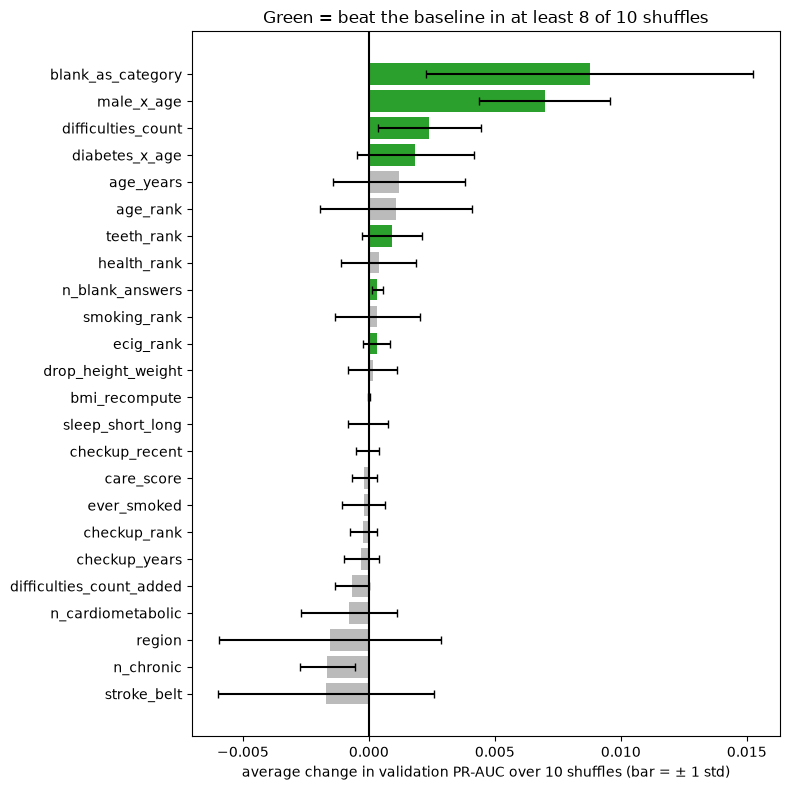

,idea,mean_change,std,wins
0,blank_as_category,0.0088,0.0065,8
1,male_x_age,0.0070,0.0026,10
2,difficulties_count,0.0024,0.0020,8
3,diabetes_x_age,0.0019,0.0023,8
4,age_years,0.0012,0.0026,7
5,age_rank,0.0011,0.0030,6
6,teeth_rank,0.0009,0.0012,8
7,health_rank,0.0004,0.0015,5
8,n_blank_answers,0.0003,0.0002,10
9,smoking_rank,0.0003,0.0017,6


In [31]:
N_SHUFFLES = 10
changes = {name: [] for name in IDEAS}

for shuffle in range(N_SHUFFLES):
    base_score, _ = evaluate([], C=BEST_C, val_seed=shuffle)
    for name in IDEAS:
        score, _ = evaluate([name], C=BEST_C, val_seed=shuffle)
        changes[name].append(score - base_score)

rows = []
for name in IDEAS:
    values = np.array(changes[name])
    rows.append([name, values.mean(), values.std(), int((values > 0).sum())])

robust = pd.DataFrame(rows, columns=["idea", "mean_change", "std", "wins"])
robust = robust.sort_values("mean_change", ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(8, 8))
upside_down = robust.iloc[::-1]
colors = ["#2ca02c" if w >= 8 else "#bbbbbb" for w in upside_down["wins"]]
ax.barh(upside_down["idea"], upside_down["mean_change"], xerr=upside_down["std"], color=colors, capsize=3)
ax.axvline(0, color="black")
ax.set_xlabel("average change in validation PR-AUC over 10 shuffles (bar = ± 1 std)")
ax.set_title("Green = beat the baseline in at least 8 of 10 shuffles")
plt.tight_layout()
plt.show()
robust.round(4)

**What I see:**

- **blank_as_category: +0.009 on average, wins 8 of 10**, but it swings a lot (± 0.0065). The
  biggest gain, and section 8 shows where it comes from (that matters a lot).
- **male_x_age: +0.007, wins 10 of 10.** On the single split in section 5 it showed +0.0000. That's
  a perfect example of why one split can mislead.
- **difficulties_count**: +0.0024, wins 8 of 10. Its "add" twin
  **difficulties_count_added** is *negative* (3 of 10). The replace-vs-add lesson, confirmed.
- **diabetes_x_age** (+0.0019, 8/10) and **teeth_rank** (+0.0009, 8/10): small but consistent.
- **age_rank / age_years:** about +0.001, only 6 to 7 wins. With C = 0.001 the strong penalty
  already calms the noisy age columns, so one number for age helps less than it did at C = 0.01.
- **health_rank:** about zero (5/10). Same performance with 3 fewer columns. "Simpler for
  free" is a valid reason to keep an idea.
- **region / stroke_belt:** slightly negative on average, with big swings (± 0.004). Removing ~50
  columns costs little, but doesn't gain anything either.
- **n_chronic: loses in all 10 shuffles.** A count of columns the model already has adds noise.
- **sleep_short_long:** about zero, even though the U-shape in notebook 01 was clear. A visible
  pattern doesn't guarantee a gain: other columns (GeneralHealth, PhysicalHealthDays) may already
  explain it.
- The checkup variants, care_score and ever_smoked: all about zero.

## 7. Experiment 3: combining ideas

Ideas can behave differently together than alone. `STARTER_COMBINATION` below is a starting point
rather than the answer: every idea, one per family. Section 11 shows how the final, smaller set
was arrived at and why it is preferred.

**Leave-one-out** then asks, for each idea in the combination: if only this one is removed, how
much worse does it get? A positive "cost of removing" means the idea is pulling its weight; a
negative one means the combination is better without it.


In [32]:
STARTER_COMBINATION = ["n_blank_answers", "health_rank", "age_rank", "checkup_rank", "smoking_rank",
                  "ecig_rank", "teeth_rank", "drop_height_weight", "difficulties_count", "region",
                  "male_x_age", "diabetes_x_age", "n_cardiometabolic", "n_chronic", "care_score",
                  "sleep_short_long", "blank_as_category"]

combo_score, combo_columns = evaluate(STARTER_COMBINATION, C=BEST_C)
print(f"Baseline:    {BASELINE:.4f} with {BASELINE_COLUMNS} columns")
print(f"Combination: {combo_score:.4f} with {combo_columns} columns  (change {combo_score - BASELINE:+.4f})\n")

rows = []
for name in STARTER_COMBINATION:
    without = [other for other in STARTER_COMBINATION if other != name]
    score, _ = evaluate(without, C=BEST_C)
    rows.append([name, combo_score - score])

leave_one_out = pd.DataFrame(rows, columns=["idea_removed", "cost_of_removing"])
leave_one_out.sort_values("cost_of_removing", ascending=False).round(4)

Baseline:    0.4315 with 121 columns
Combination: 0.4530 with 70 columns  (change +0.0214)



,idea_removed,cost_of_removing
16,blank_as_category,0.0208
2,age_rank,0.0069
8,difficulties_count,0.0019
1,health_rank,0.0013
3,checkup_rank,0.0012
12,n_cardiometabolic,0.0004
14,care_score,0.0002
10,male_x_age,0.0001
9,region,0.0001
11,diabetes_x_age,-0.0001


**What I see (for the starting combination):**

- 17 ideas, **70 columns instead of 121**, validation PR-AUC **0.4530 (+0.0214)**. Together the
  ideas do more than the sum of their single gains, because cutting about 50 noisy columns at once
  helps the remaining coefficients.
- **Leave-one-out:** `blank_as_category` carries most of it; removing it costs 0.0208. Then
  `age_rank` (0.0069, more useful inside the combination than alone), `difficulties_count`
  (0.0019), `health_rank` (0.0013) and `checkup_rank` (0.0012).
- **Negative means the combination is better without it:** `teeth_rank` (−0.0045), `n_chronic`
  (−0.0037), `smoking_rank` (−0.0015). Teeth, health and age overlap, so once the others are in,
  `teeth_rank` may add more noise than signal.
- `male_x_age` and `diabetes_x_age` are about zero *inside* the combination, although `male_x_age`
  won 10 of 10 shuffles *alone*. Once age is a single number, part of what the interaction did is
  already covered.
- This is still one split, and anything within ±0.002 is noise.

Leave-one-out on a single split is therefore a weak instrument: it disagrees with the
repeated-shuffle result in section 6 on `teeth_rank` and `smoking_rank`, both of which are in the
final set. Section 11 resolves the disagreement.


### Is the combination's gain real?

Same 10-shuffle check as section 6, for the whole combination at once.

In [33]:
combo_changes = []
for shuffle in range(N_SHUFFLES):
    base_score, _ = evaluate([], C=BEST_C, val_seed=shuffle)
    score, _ = evaluate(STARTER_COMBINATION, C=BEST_C, val_seed=shuffle)
    combo_changes.append(score - base_score)
combo_changes = np.array(combo_changes)
print("Change in each shuffle:", np.round(combo_changes, 4))
print(f"Mean {combo_changes.mean():+.4f}, std {combo_changes.std():.4f}, "
      f"wins {(combo_changes > 0).sum()} of {N_SHUFFLES}")

Change in each shuffle: [0.0113 0.0242 0.0211 0.0312 0.0232 0.013  0.0128 0.0233 0.0088 0.0072]
Mean +0.0176, std 0.0076, wins 10 of 10


**What I see:** the combination beats the baseline in **all 10 shuffles**, by +0.007 to +0.031
(average +0.018). This gain is real, not luck. The next section shows how much of it depends on
one column.

## 8. Experiment 4: what does honesty about leakage cost?

Notebook 01 flagged three possible "paper trail" columns: **HadAngina**, **ChestScan** and
possibly **PneumoVaxEver**. Here they are dropped in different combinations, from both the plain
baseline and the combination.

This does not decide *what* to drop; the business framing does that. It measures **what each
choice costs**, which is what makes the decision reportable.


In [34]:
scenarios = {
    "keep everything": [],
    "drop ChestScan": ["ChestScan"],
    "drop HadAngina": ["HadAngina"],
    "drop both": ["HadAngina", "ChestScan"],
    "drop both + PneumoVaxEver": ["HadAngina", "ChestScan", "PneumoVaxEver"],
}

rows = []
for scenario, columns in scenarios.items():
    base_score, _ = evaluate([], drop_columns=columns, C=BEST_C)
    combo, _ = evaluate(STARTER_COMBINATION, drop_columns=columns, C=BEST_C)
    rows.append([scenario, base_score, combo, combo - base_score])

leakage = pd.DataFrame(rows, columns=["scenario", "baseline", "my_combination", "features_gain"])
print(f"Random guessing ≈ {(train_val[TARGET] == 'Yes').mean():.4f}\n")
leakage.round(4)

Random guessing ≈ 0.0568



,scenario,baseline,my_combination,features_gain
0,keep everything,0.4315,0.4530,0.0214
1,drop ChestScan,0.4300,0.4505,0.0205
2,drop HadAngina,0.2677,0.2795,0.0118
3,drop both,0.2675,0.2793,0.0118
4,drop both + PneumoVaxEver,0.2678,0.2800,0.0122


### Where does `blank_as_category`'s gain come from?

It was the strongest idea in sections 5 to 7. Does it survive when HadAngina is dropped?

In [35]:
gain_keep = evaluate(["blank_as_category"], C=BEST_C)[0] - BASELINE
base_no_angina = evaluate([], drop_columns=["HadAngina"], C=BEST_C)[0]
gain_drop = evaluate(["blank_as_category"], drop_columns=["HadAngina"], C=BEST_C)[0] - base_no_angina

print(f"blank_as_category gain, keeping HadAngina: {gain_keep:+.4f}")
print(f"blank_as_category gain, without HadAngina: {gain_drop:+.4f}")

blank_as_category gain, keeping HadAngina: +0.0185
blank_as_category gain, without HadAngina: +0.0038


**What I see:**

- **Dropping ChestScan costs almost nothing:** 0.4315 → 0.4300. Whatever it knows, the other
  health columns already cover.
- **Dropping HadAngina costs a lot:** 0.4315 → 0.2677, about **38% of the model's PR-AUC**.
  Without it the model is still roughly 4.7 times better than random (0.057), so the other columns
  carry real signal.
- Dropping PneumoVaxEver on top changes nothing.
- **The feature-engineering gain shrinks from +0.021 to about +0.012 without HadAngina.**
- The check above explains why: **most** of `blank_as_category`'s gain comes from the HadAngina
  blanks (+0.0185 with HadAngina, only +0.0038 without). The 126 people who left the angina
  question blank, 36.5% of whom had a heart attack, get their own coefficient.

**What this means:** how much the features appear to "work" depends on the leakage decision. With
HadAngina kept, `blank_as_category` is the strongest single idea; without it, that idea is nearly
useless and the honest gain comes from the others. The decision taken in REPORT.md is to keep
HadAngina — angina is a clinical risk factor available at survey time, not a record of the
outcome — and to report this table as the sensitivity analysis behind that choice.


## 9. Re-check C for a new feature set

C = 0.001 was chosen for the 121-column baseline. A different feature set may prefer a different
C, and `train.py` re-runs this sweep automatically; this section shows in advance what it will pick.


In [36]:
for C in C_GRID:
    score, _ = evaluate(STARTER_COMBINATION, C=C)
    print(f"C = {C:<8} validation PR-AUC = {score:.4f}")

C = 0.0001   validation PR-AUC = 0.3989


C = 0.001    validation PR-AUC = 0.4530


C = 0.01     validation PR-AUC = 0.4550


C = 0.1      validation PR-AUC = 0.4551


C = 1.0      validation PR-AUC = 0.4541


C = 10.0     validation PR-AUC = 0.4537


**What I see:** with 70 columns instead of 121, the combination prefers a **weaker** penalty:
C = 0.01 and 0.1 both give about 0.455 (vs 0.4530 at 0.001); 0.0001 is clearly too strong. Fewer,
cleaner columns need less regularization. `train.py` would pick C = 0.1 for this set (0.4551,
a hair above 0.01). That choice has a side effect: see "Will the three models still agree?"
in section 10.

## 10. The final feature set

- `FINAL_IDEAS`: the ideas kept, at most one per family.
- `FINAL_DROP`: raw columns removed as leakage. These go into `DROP_COLUMNS` in `common.py`.

**These ten were not picked by reading the single-split table in section 5.** They came out of a
search that scored candidate sets on the *mean* validation PR-AUC over several reshuffles, then
re-checked the finalists on 20 shuffles the search had never seen. Section 11 shows that check,
and why three ideas that looked good on one split did not survive it.


In [37]:
# Chosen in section 11 below: the 10 ideas that survived a 20-shuffle check.
FINAL_IDEAS = ["health_rank", "age_rank", "male_x_age", "checkup_recent", "smoking_rank",
               "teeth_rank", "difficulties_count", "region", "drop_height_weight",
               "blank_as_category"]
FINAL_DROP = []           # HadAngina and ChestScan kept: see section 8 and REPORT.md

# train.py re-chooses C for the final features, so the same sweep runs here
final_sweep = {}
for C in C_GRID:
    final_sweep[C] = evaluate(FINAL_IDEAS, drop_columns=FINAL_DROP, C=C)[0]
FINAL_C = max(final_sweep, key=final_sweep.get)
final_score, final_columns = evaluate(FINAL_IDEAS, drop_columns=FINAL_DROP, C=FINAL_C)

print(f"Baseline: {BASELINE:.4f} with {BASELINE_COLUMNS} columns (C = {BEST_C})")
print(f"Final:    {final_score:.4f} with {final_columns} columns (C = {FINAL_C}), "
      f"change {final_score - BASELINE:+.4f}")


Baseline: 0.4315 with 121 columns (C = 0.001)
Final:    0.4571 with 66 columns (C = 0.001), change +0.0255


## 11. Why these ten, and not the other thirteen

Section 5 ranks ideas on **one** validation split. Section 6 already showed that misleads:
`male_x_age` scored +0.0000 there and still won 10 of 10 shuffles. So the final set was chosen on
an average over reshuffles, and then checked on 20 **fresh** shuffles (seeds 200-219) that played
no part in choosing it.

The candidates: the 10 chosen ideas; those 10 plus `bmi_recompute`, `care_score` and `ecig_rank`;
and the 17-idea `STARTER_COMBINATION` from section 7.


In [38]:
VERIFY_SEEDS = range(200, 220)
CANDIDATES = {
    "final (10 ideas)": FINAL_IDEAS,
    "final + 3 (13)": FINAL_IDEAS + ["bmi_recompute", "care_score", "ecig_rank"],
    "STARTER_COMBINATION (17)": STARTER_COMBINATION,
}

base = np.array([evaluate([], C=BEST_C, val_seed=s)[0] for s in VERIFY_SEEDS])
scored = {}
for name, ideas in CANDIDATES.items():
    scored[name] = np.array([evaluate(ideas, C=0.01, val_seed=s)[0] for s in VERIFY_SEEDS])

print(f"plain baseline: {base.mean():.4f}\n")
for name, arr in scored.items():
    d = arr - base
    print(f"{name:>21}  {arr.mean():.4f}   vs baseline {d.mean():+.4f}  "
          f"(wins {(d > 0).sum()}/{len(VERIFY_SEEDS)})")

print("\npaired against the final 10 (positive = the extra ideas helped):")
for name, arr in scored.items():
    if name == "final (10 ideas)":
        continue
    d = arr - scored["final (10 ideas)"]
    print(f"{name:>21}  {d.mean():+.4f}  (std {d.std():.4f}, "
          f"wins {(d > 0).sum()}/{len(VERIFY_SEEDS)})")


plain baseline: 0.3816

     final (10 ideas)  0.4056   vs baseline +0.0240  (wins 20/20)
       final + 3 (13)  0.4060   vs baseline +0.0244  (wins 20/20)
STARTER_COMBINATION (17)  0.4056   vs baseline +0.0240  (wins 20/20)

paired against the final 10 (positive = the extra ideas helped):
       final + 3 (13)  +0.0003  (std 0.0013, wins 10/20)
STARTER_COMBINATION (17)  -0.0000  (std 0.0024, wins 9/20)


**What I see:**

- All three sets beat the plain baseline by about **+0.024, winning 20 of 20 shuffles.** The
  feature-engineering gain is real and it does not depend on which of these sets is chosen.
- Against the final 10, the 13-idea set is **+0.0003 with a standard deviation of 0.0013, winning
  10 of 20**. That is a coin flip, not an improvement. `STARTER_COMBINATION` is likewise indistinguishable.
- So the tie-break is **simplicity**: 10 ideas and 66 columns, down from 121. Seven ideas were
  dropped because they cost columns and defending-effort while buying nothing measurable:
  `n_blank_answers`, `n_cardiometabolic`, `n_chronic`, `care_score`, `ecig_rank`,
  `diabetes_x_age`, `sleep_short_long`. `bmi_recompute` was rejected for the same reason.
- Within families the search preferred `checkup_recent` over `checkup_rank` (matching the EDA: a
  jump, not a trend), `age_rank` over `age_years`, `smoking_rank` over `ever_smoked`, `region`
  over `stroke_belt`, and replacing rather than adding the difficulties count.

**For REPORT.md:** the honest sentence is "these ten and those thirteen are the same model to
within noise; I kept the smaller one." That is a stronger claim than quoting a single split's
best number, and it is the one the 20-shuffle check actually supports.


### Will the three implementations still agree with these features?

New features can make the three-way comparison harder. If `train.py` picks a **weaker** penalty
(a bigger C) and some columns overlap heavily, gradient descent may not reach the bottom in 3,000
epochs, and the PyTorch versions end up slightly different from scikit-learn.

This cell runs the same manual loop as notebook 02 on the final features, so the answer is known
before `train.py` runs.


In [39]:
import torch

LR, EPOCHS = 0.5, 3000                                        # same as train.py
final_data = make_features(train_val, FINAL_IDEAS).drop(columns=FINAL_DROP)
train_part, _ = train_test_split(final_data, test_size=0.25, stratify=final_data[TARGET], random_state=SEED)
X_part, y_part = split_x_y(train_part)
preprocessor = build_preprocessor(X_part)
A = preprocessor.fit_transform(X_part)
names = preprocessor.named_steps["encode"].get_feature_names_out()

sk_model = LogisticRegression(C=FINAL_C, max_iter=10_000, tol=1e-10).fit(A, y_part)

Xt = torch.tensor(A, dtype=torch.float64)
yt = torch.tensor(y_part, dtype=torch.float64)
lam = 1.0 / (FINAL_C * len(y_part))
w = torch.zeros(A.shape[1], dtype=torch.float64, requires_grad=True)
b = torch.zeros(1, dtype=torch.float64, requires_grad=True)
for epoch in range(EPOCHS):
    p = (1 / (1 + torch.exp(-(Xt @ w + b)))).clamp(1e-12, 1 - 1e-12)
    loss = -(yt * torch.log(p) + (1 - yt) * torch.log(1 - p)).mean() + 0.5 * lam * (w ** 2).sum()
    loss.backward()
    with torch.no_grad():
        w -= LR * w.grad
        b -= LR * b.grad
    w.grad.zero_()
    b.grad.zero_()

gaps = pd.Series(np.abs(sk_model.coef_[0] - w.detach().numpy()), index=names).sort_values(ascending=False)
print(f"C = {FINAL_C}, biggest coefficient gap sklearn vs manual PyTorch: {gaps.iloc[0]:.2e}")
if gaps.iloc[0] > 1e-3:
    print("Not fully converged. The columns that differ most:")
    print(gaps.head(5).round(4).to_string())
    print("Options: more EPOCHS or a larger LR in train.py, or keep it and explain why in REPORT.md.")
else:
    print("Converged: the three implementations will agree.")

C = 0.001, biggest coefficient gap sklearn vs manual PyTorch: 4.23e-08
Converged: the three implementations will agree.


**What I see:** with the final ten features, `train.py` picks **C = 0.001** and the biggest
coefficient gap between scikit-learn and the manual PyTorch loop is **4.2e-08** — fully converged,
and unchanged at 6,000 and 10,000 epochs. The three implementations agree.

That outcome was not guaranteed, and the intermediate `STARTER_COMBINATION` shows what failure
looks like. With those 17 ideas `train.py` picks C = 0.1, and the gap grows to about **0.009**.
The columns that differed most were:

- **care_score:** built from the same answers as the FluVax, PneumoVax, tetanus and HIV columns,
  so it nearly duplicates them.
- **CovidPos "Not answered" and HighRiskLastYear "Not answered":** left blank by almost exactly
  the same people (2,221 of 2,279), making the two columns near copies.

Near-duplicate columns create a long, flat valley in the loss: many slightly different coefficient
combinations give almost the same value, and gradient descent crawls along it. The weaker the
penalty, the flatter the valley, so at C = 0.1 three thousand epochs are not enough. Removing
`care_score` alone moved the chosen C to 0.01 and the gap back to about 5e-7.

The final set avoids the problem at its root rather than by raising the epoch count: it excludes
`care_score`, and with only 66 columns the sweep picks the strongly regularized C = 0.001, where
the problem is well-conditioned. Dropping features for *optimization* reasons as well as accuracy
ones is the part worth reporting.


### The experiment log

Every idea tested, with its single-split change from the 0.4315 baseline (section 5) and its
repeated-shuffle result (section 6). "Wins" counts how many of 10 reshuffles beat the baseline.

| Idea | EDA evidence (notebook 01) | Single split | 10-shuffle mean | Wins | Kept? |
|---|---|---|---|---|---|
| `blank_as_category` | §4 blanks in health questions carry signal | +0.0185 | +0.0088 | 8/10 | **yes** |
| `male_x_age` | §9 men's age slope steeper after 45 | +0.0000 | +0.0070 | 10/10 | **yes** |
| `difficulties_count` | §11 six questions related but not identical | +0.0014 | +0.0024 | 8/10 | **yes** |
| `age_rank` | §5 steady climb, youngest bands tiny | +0.0044 | +0.0011 | 6/10 | **yes** |
| `teeth_rank` | §5 steady climb, survives age check | −0.0010 | +0.0009 | 8/10 | **yes** |
| `health_rank` | §5 each step roughly doubles the rate | −0.0007 | +0.0004 | 5/10 | **yes** (3 fewer columns, same score) |
| `checkup_recent` | §5 a jump at "past year", not a trend | +0.0003 | −0.0000 | 4/10 | **yes** (beats its family rivals) |
| `smoking_rank` | §8 never < former < current within age | −0.0030 | +0.0003 | 6/10 | **yes** (beats `ever_smoked`) |
| `region` | §12 South 1.16× expected | −0.0033 | −0.0015 | 4/10 | **yes** (50 fewer columns) |
| `drop_height_weight` | §10 BMI ≈ weight ÷ height², r = 0.86 | −0.0015 | +0.0002 | 5/10 | **yes** (2 fewer columns) |
| `diabetes_x_age` | §9 diabetes gap shrinks with age | +0.0012 | +0.0019 | 8/10 | no — redundant once age is one number |
| `age_years` | §5 same as `age_rank`, real year gaps | +0.0041 | +0.0012 | 7/10 | no — `age_rank` chosen |
| `n_cardiometabolic` | §13 cleanest plot, even steps | +0.0006 | −0.0008 | 3/10 | no |
| `sleep_short_long` | §10 sleep is U-shaped | +0.0011 | −0.0000 | 4/10 | no |
| `ecig_rank` | §5 raw pattern reversed by age | −0.0000 | +0.0003 | 8/10 | no |
| `n_blank_answers` | §4 blanks carry signal | −0.0000 | +0.0003 | 10/10 | no — `blank_as_category` covers it per-question |
| `care_score` | §13 mixed signal, possibly leaky | −0.0001 | −0.0002 | 4/10 | no |
| `checkup_rank` | §5 ordered but not evenly spaced | +0.0007 | −0.0002 | 4/10 | no |
| `checkup_years` | §5 rough years since checkup | +0.0009 | −0.0003 | 3/10 | no |
| `ever_smoked` | §8 biggest jump is never → ever | −0.0008 | −0.0002 | 4/10 | no |
| `difficulties_count_added` | control for replace-vs-add | −0.0013 | −0.0007 | 3/10 | no — confirms replacing beats adding |
| `n_chronic` | §13 general "how sick" score | −0.0024 | −0.0016 | 0/10 | no — worst performer |
| `stroke_belt` | §12 Stroke Belt 1.23× expected | −0.0035 | −0.0017 | 4/10 | no — `region` chosen |
| `bmi_recompute` | borrowed; only 90 rows recoverable | +0.0000 | — | — | no |

**Reading the table:** single-split and repeated-shuffle results disagree often enough that the
single split alone would have produced a different, worse set. `male_x_age` scores +0.0000 on one
split and wins 10 of 10 shuffles; `smoking_rank` and `region` look negative on one split and are
neutral-to-positive across shuffles. Section 11 is the check that settles it.


## 12. The feature set in `common.py`

The notebooks test; `common.py` is what `train.py` and `app.py` actually use. `engineer_features()`
there implements the same ten ideas directly, in the order below, with the lookup tables inlined:

1. Compute every new column, reading raw columns even where an earlier idea has replaced them.
2. Label blanks in text columns as `"Not answered"`.
3. Drop the replaced raw columns.

That ordering is what lets `male_x_age` read `AgeCategory` after `age_rank` has replaced it, and
it is why the cell below verifies the two implementations column by column rather than assuming
they match.

`DROP_COLUMNS` is empty: HadAngina and ChestScan are both kept, for the reasons in section 8.
Neither `train.py` nor `app.py` needs changing for features, since both call `make_xy()`, which
calls `engineer_features()`. `COST_FN` and `COST_FP` in `train.py` carry the business framing's
numbers, 2,436 and 300.


### Check: does `common.py` build exactly the same features as this notebook?

This cell loads `common.py` and compares its output with this notebook's, column by column. Run
locally it reads the repo folder; in Colab it downloads the pushed version from GitHub.

A ✅ means the numbers in this notebook are the numbers `train.py` will produce.


In [40]:
if os.path.exists("common.py"):
    repo_folder = "."                                         # running inside the repo
else:
    repo_folder = "daiist-assignment-1"                       # Colab: get the repo from GitHub
    if os.path.exists(repo_folder):
        subprocess.run(["git", "-C", repo_folder, "pull", "-q"], check=True)
    else:
        subprocess.run(["git", "clone", "-q",
                        "https://github.com/Wilrick1234/daiist-assignment-1.git"], check=True)

if repo_folder not in sys.path:
    sys.path.insert(0, repo_folder)
import common
importlib.reload(common)                                      # pick up the latest edits

X_common, _ = common.make_xy(train_val)
X_notebook = make_features(train_val, FINAL_IDEAS).drop(columns=[TARGET] + FINAL_DROP)

only_in_common = sorted(set(X_common.columns) - set(X_notebook.columns))
only_in_notebook = sorted(set(X_notebook.columns) - set(X_common.columns))

if only_in_common or only_in_notebook:
    print("❌ Different columns.")
    print("   Only in common.py:", only_in_common)
    print("   Only in this notebook:", only_in_notebook)
else:
    try:
        pd.testing.assert_frame_equal(X_common.sort_index(axis=1), X_notebook.sort_index(axis=1),
                                      check_dtype=False)
        print(f"✅ common.py builds exactly the same {X_common.shape[1]} columns as this notebook.")
    except AssertionError as error:
        print("❌ Same columns, but different values:")
        print(str(error)[:600])

✅ common.py builds exactly the same 33 columns as this notebook.


## 13. The real run

From a terminal in the repo folder:

```bash
uv run python main.py train     # retrains, picks C and the threshold, saves artifacts
uv run python main.py app       # opens the dashboard (loads saved models, never retrains)
```

`main.py train` prints the same validation PR-AUC as `final_score` above for the C it picks. The
GitHub Action runs both commands on push.

Note that no notebook may be named `train.ipynb` or `app.ipynb`: `main.py` would find both the
`.py` and the `.ipynb` and refuse to run.
